# 🚦 Traffic Sign Detection — PyTorch (YOLOv8 baseline)

Baseline YOLOv8n detector (15 classes, Kaggle `pkdarabi/cardetection`) and its analytics.

> ⚠ **SMOKE_TEST = False** in cell 0 → full 75-epoch run. Set `SMOKE_TEST = True` for a 1-epoch check.


In [52]:
# 0 · Setup ----------------------------------------------------------------
import os, time, random, json, zipfile, urllib.request, shutil
from pathlib import Path
from PIL import Image

import numpy as np
import pandas as pd
import cv2
import yaml
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset, Dataset
from torchvision import transforms, models

from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             f1_score, confusion_matrix)

ROOT      = Path(".").resolve()
DATA_DIR  = ROOT / "database"
OUT_DIR   = ROOT / "outputs"; OUT_DIR.mkdir(exist_ok=True)
MODEL_DIR = ROOT / "models";  MODEL_DIR.mkdir(exist_ok=True)

DET_DIR   = DATA_DIR / "car"        # Traffic Signs Detection (YOLO format)
DET_YAML  = DET_DIR / "signs_data.yaml"

SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = True

print("PyTorch :", torch.__version__)
print("CUDA    :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU     :", torch.cuda.get_device_name(0))
print("device  :", device := torch.device("cuda" if torch.cuda.is_available() else "cpu"))

# final-training switch: False = full real run (YOLO 75 epochs);
# True = 1-epoch smoke check of the whole pipeline (results NOT final)
SMOKE_TEST = False

PyTorch : 2.14.1+cu126
CUDA    : True
GPU     : NVIDIA GeForce RTX 3060 Laptop GPU
device  : cuda


## 1 · Dataset — verification

Traffic Signs Detection (YOLO format) must already be extracted under `database/car`


In [53]:
# 1.1 · Verify datasets & write canonical data.yaml (absolute paths)
assert DET_YAML.exists() or (DET_DIR / "data.yaml").exists(), f"detection dataset missing in {DET_DIR}"

DET_CLASSES = ["Green Light", "Red Light", "Speed Limit 10", "Speed Limit 100",
               "Speed Limit 110", "Speed Limit 120", "Speed Limit 20", "Speed Limit 30",
               "Speed Limit 40", "Speed Limit 50", "Speed Limit 60", "Speed Limit 70",
               "Speed Limit 80", "Speed Limit 90", "Stop"]

with open(DET_YAML, "w", encoding="utf-8") as f:
    yaml.safe_dump({"path": str(DET_DIR.resolve()),
                    "train": "train/images", "val": "valid/images", "test": "test/images",
                    "nc": len(DET_CLASSES), "names": DET_CLASSES}, f, sort_keys=False)

n_obj = 0
for split in ("train", "valid", "test"):
    imgs = sorted((DET_DIR / split / "images").glob("*"))
    lbls = sorted((DET_DIR / split / "labels").glob("*.txt"))
    n_obj += sum(1 for p in lbls for line in p.read_text().splitlines() if line.strip())
    print(f"{split:6s}: {len(imgs):5d} images | {len(lbls):5d} label files")
print("total annotated objects:", n_obj)



train :  3530 images |  3530 label files
valid :   801 images |   801 label files
test  :   638 images |   638 label files
total annotated objects: 6012
GTSRB: train 39,209 | test 12,630 | classes 43


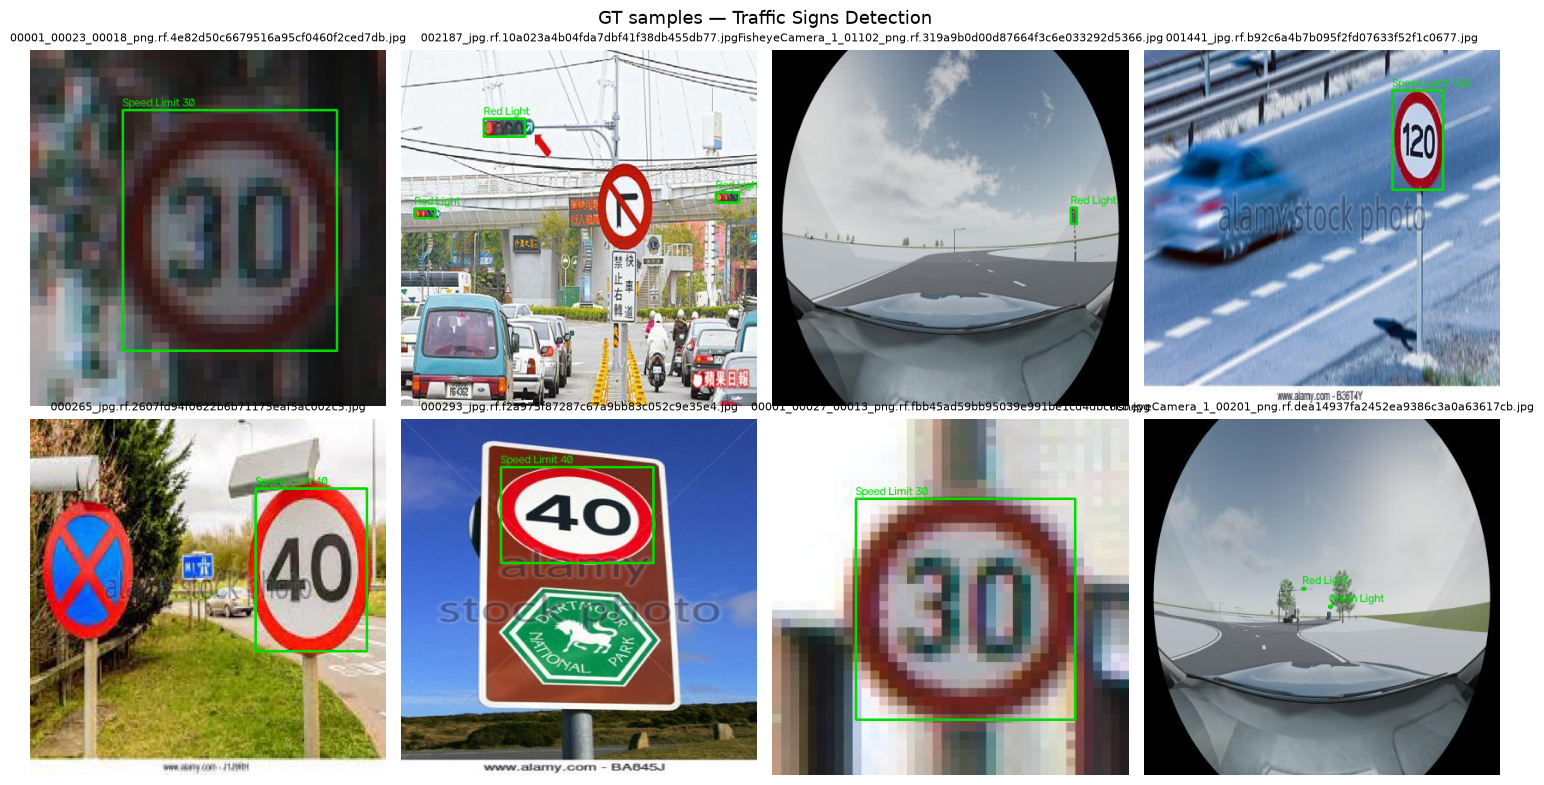

In [54]:
# 1.2 · Visualize ground-truth annotation boxes
train_imgs = sorted((DET_DIR / "train" / "images").glob("*"))
rng        = np.random.default_rng(SEED)
samples    = list(rng.choice(train_imgs, size=8, replace=False))

fig, axes = plt.subplots(2, 4, figsize=(15, 8))
for ax, img_path in zip(axes.ravel(), samples):
    img = cv2.imread(str(img_path))
    H, W = img.shape[:2]
    lbl = (DET_DIR / "train" / "labels" / (img_path.stem + ".txt"))
    if lbl.exists():
        for line in lbl.read_text().splitlines():
            if not line.strip():
                continue
            c, cx, cy, w, h = map(float, line.split())
            x1, y1 = int((cx - w / 2) * W), int((cy - h / 2) * H)
            bw, bh = int(w * W), int(h * H)
            cv2.rectangle(img, (x1, y1), (x1 + bw, y1 + bh), (0, 220, 0), 2)
            cv2.putText(img, DET_CLASSES[int(c)], (x1, max(12, y1 - 4)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 220, 0), 1, cv2.LINE_AA)
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(img_path.name, fontsize=8)
    ax.axis("off")
plt.suptitle("GT samples — Traffic Signs Detection", fontsize=13)
plt.tight_layout(); plt.show()

## 2 · Detection — YOLOv8 training (75 epochs)

`USE_PRETRAINED=True` → transfer learning from COCO weights; `False` → random init.
75 epochs with cosine LR, mosaic disabled over the last 15 epochs for stability,
checkpoint snapshot every 10 epochs. Expect ≈ 35–40 min on a laptop GPU (reduce
`DET_EPOCHS` on CPU).

In [55]:
# 2.1 · Build & train YOLOv8n

# — §2 self-boot — no-op when cell 0 already ran; lets this section run on a fresh kernel —
import time, random
from pathlib import Path
import numpy as np, pandas as pd, cv2, yaml
import matplotlib.pyplot as plt
import torch
if 'DET_YAML' not in globals():          # cell 0 (Setup) hasn't run in this kernel
    _root    = Path('.').resolve()
    SEED     = 42
    device   = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    DET_DIR  = _root / 'database' / 'car'
    DET_YAML = DET_DIR / 'signs_data.yaml'
    assert DET_YAML.exists(), f'{DET_YAML} missing — run cell 0 + 1.1 first (Run All does this)'
    torch.manual_seed(SEED); np.random.seed(SEED)
    print('· §2 prerequisites auto-booted (cell 0 had not run in this kernel)')

from ultralytics import YOLO

USE_PRETRAINED = True          # True = transfer learning / False = train from scratch
DET_EPOCHS     = 1 if globals().get('SMOKE_TEST', False) else 75
if DET_EPOCHS == 1:
    print('⚠ SMOKE TEST — 1 epoch; set SMOKE_TEST = False in cell 0 for the full 75-epoch training')

det_model = YOLO("yolov8n.pt" if USE_PRETRAINED else "yolov8n.yaml")
print("starting weights:", "yolov8n.pt (COCO transfer)" if USE_PRETRAINED else "yolov8n.yaml (random init)")

results = det_model.train(
    data=str(DET_YAML), epochs=DET_EPOCHS, imgsz=416, batch=16,
    project="runs", name="yolov8n_traffic_signs", exist_ok=False,
    device=0 if torch.cuda.is_available() else "cpu",
    seed=SEED, patience=25, cos_lr=True, close_mosaic=15, save_period=10,
    workers=0, plots=True,
)
det_run_dir = Path(results.save_dir)
BEST_PT     = det_run_dir / "weights" / "best.pt"
print("best checkpoint →", BEST_PT)

starting weights: yolov8n.pt (COCO transfer)
New https://pypi.org/project/ultralytics/8.4.201 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.183  Python-3.14.7 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 3060 Laptop GPU, 6144MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=15, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=D:\devprojects\Project Traffic signs\database\car\signs_data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=75, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, iou=0.7, kobj=1.0, line_width

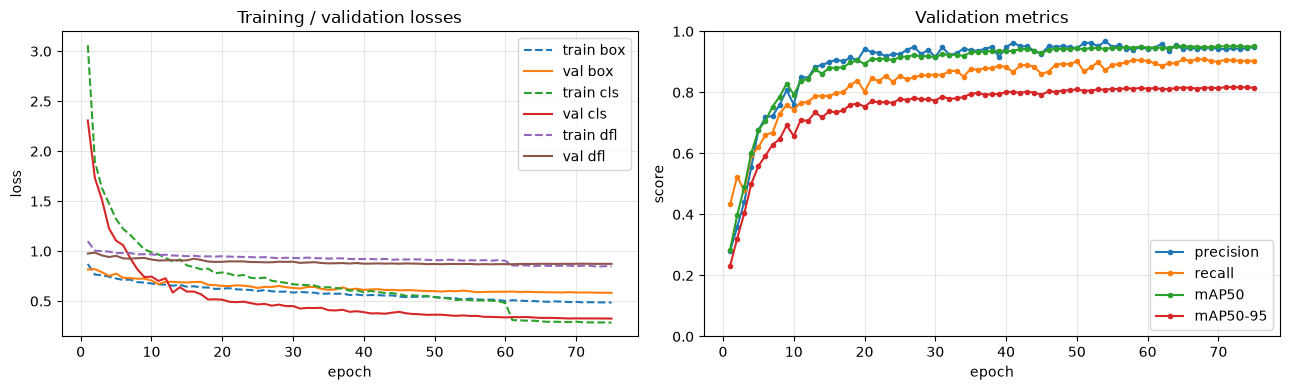

In [56]:
# 2.2 · Training curves (parsed from results.csv)
df = pd.read_csv(det_run_dir / "results.csv")
df.columns = [c.strip() for c in df.columns]
epoch = df["epoch"]

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for loss in ("box", "cls", "dfl"):
    ax[0].plot(epoch, df[f"train/{loss}_loss"], "--", label=f"train {loss}")
    ax[0].plot(epoch, df[f"val/{loss}_loss"],    label=f"val {loss}")
ax[0].set(title="Training / validation losses", xlabel="epoch", ylabel="loss")
ax[0].legend(); ax[0].grid(alpha=.3)

for suffix, label in (("precision(B)", "precision"), ("recall(B)", "recall"),
                      ("mAP50(B)", "mAP50"), ("mAP50-95(B)", "mAP50-95")):
    col = [c for c in df.columns if c.endswith(suffix)][0]
    ax[1].plot(epoch, df[col], marker="o", ms=3, label=label)
ax[1].set(title="Validation metrics", xlabel="epoch", ylabel="score", ylim=(0, 1))
ax[1].legend(loc="lower right"); ax[1].grid(alpha=.3)
plt.tight_layout()
plt.savefig(OUT_DIR / "yolo_training_curves.png", dpi=150)
plt.show()

In [57]:
# 2.3 · Validation & test performance (metrics table)
rows = []
for split in ("val", "test"):
    m = det_model.val(data=str(DET_YAML), split=split, verbose=False)
    rows.append({"split": split,
                 "precision": round(m.box.mp, 4), "recall": round(m.box.mr, 4),
                 "mAP50": round(m.box.map50, 4), "mAP50-95": round(m.box.map, 4)})
    if hasattr(m, "save_dir"):
        print(f"figures ({split}) →", m.save_dir)
yolo_metrics = pd.DataFrame(rows).set_index("split")
print(yolo_metrics)
yolo_metrics.to_csv(OUT_DIR / "yolo_metrics.csv")

Ultralytics 8.4.183  Python-3.14.7 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 3060 Laptop GPU, 6144MiB)
Model summary (fused): 73 layers, 3,136,109 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 199.3±61.4 MB/s, size: 20.3 KB)
val: Scanning D:\devprojects\Project Traffic signs\database\car\valid\labels.cache... 801 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 801/801 224.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 51/51 2.7it/s 18.8s<0.1s
                   all        801        944      0.943      0.905       0.95      0.818
Speed: 0.6ms preprocess, 1.9ms inference, 0.0ms loss, 1.0ms postprocess per image
Results saved to D:\devprojects\Project Traffic signs\runs\detect\val-8
figures (val) → D:\devprojects\Project Traffic signs\runs\detect\val-8
Ultralytics 8.4.183  Python-3.14.7 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 3060 Laptop GPU, 6144MiB)
Model summar

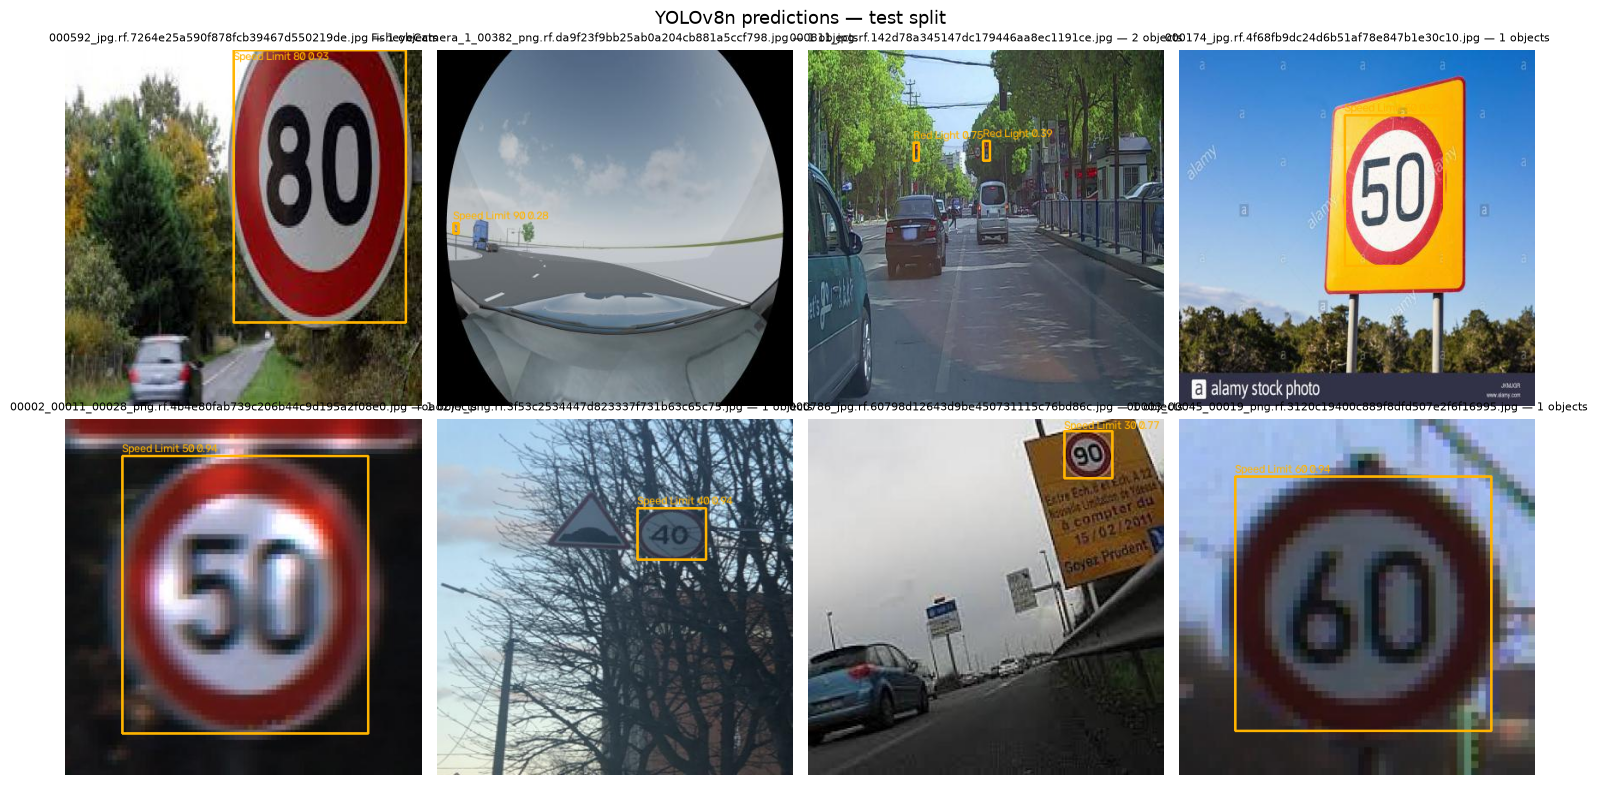

In [58]:
# 2.4 · Qualitative results on test images
test_imgs = sorted((DET_DIR / "test" / "images").glob("*"))
picks     = list(rng.choice(test_imgs, size=8, replace=False))

fig, axes = plt.subplots(2, 4, figsize=(15, 8))
for ax, p in zip(axes.ravel(), picks):
    img  = cv2.imread(str(p))
    r    = det_model.predict(source=img, conf=0.25, imgsz=416, verbose=False)[0]
    for b in r.boxes:
        x1, y1, x2, y2 = map(int, b.xyxy[0].tolist())
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 180, 255), 2)
        cv2.putText(img, f"{DET_CLASSES[int(b.cls)]} {float(b.conf):.2f}",
                    (x1, max(12, y1 - 4)), cv2.FONT_HERSHEY_SIMPLEX, 0.45,
                    (0, 180, 255), 1, cv2.LINE_AA)
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{p.name} — {len(r.boxes)} objects", fontsize=8)
    ax.axis("off")
plt.suptitle("YOLOv8n predictions — test split", fontsize=13)
plt.tight_layout(); plt.show()

## 6 · Statistics & plots — full analytics dashboard

Dataset balance, per-class detection quality (AP50), label-noise style error analysis


images per split : {'train': 3530, 'valid': 801, 'test': 638}
objects per split: {'train': np.int64(4298), 'valid': np.int64(944), 'test': np.int64(770)}


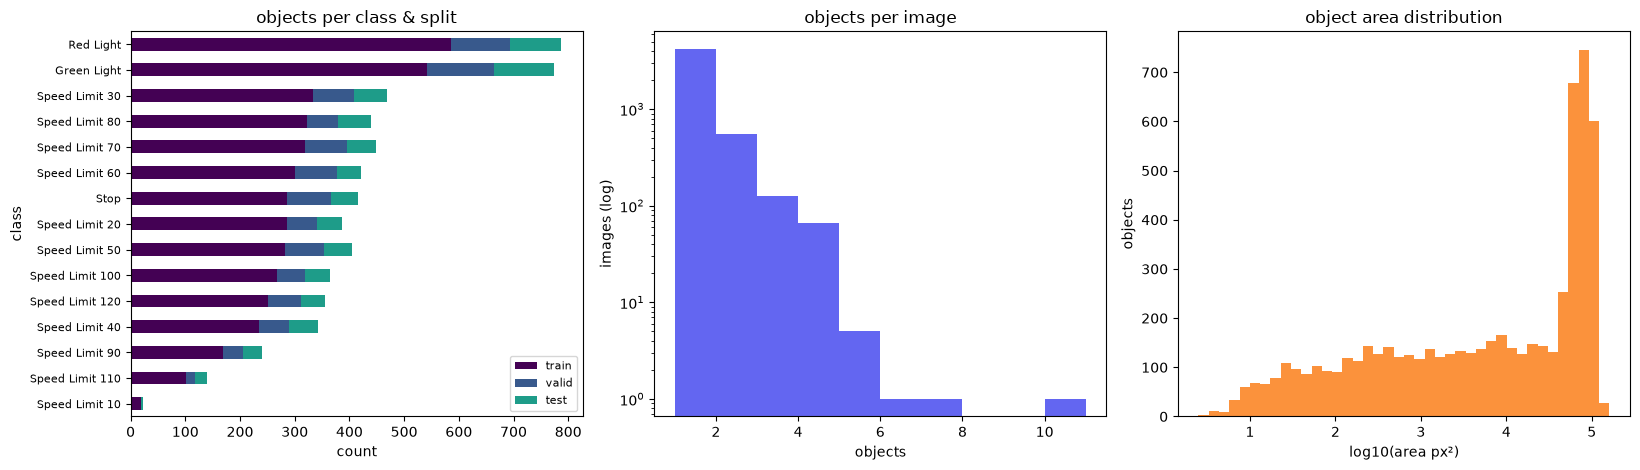

In [ ]:
def label_records():
    recs, per_img = [], []
    for split in ("train", "valid", "test"):
        for p in (DET_DIR / split / "labels").glob("*.txt"):
            lines = [l for l in p.read_text().splitlines() if l.strip()]
            per_img.append(len(lines))
            for l in lines:
                c, cx, cy, w, h = map(float, l.split())
                recs.append({"split": split, "class": DET_CLASSES[int(c)], "area": w * h * 416 * 416})
    return recs, per_img

recs, per_img = label_records()
ddf = pd.DataFrame(recs)
areas = ddf["area"].to_numpy()
count_tbl = ddf.pivot_table(index="class", columns="split", values="area", aggfunc="size")[["train", "valid", "test"]].fillna(0).astype(int)
img_counts = {s: len(list((DET_DIR / s / "images").glob("*"))) for s in ("train", "valid", "test")}
print("images per split :", img_counts)
print("objects per split:", dict(count_tbl.sum(axis=0)))
count_tbl.to_csv(OUT_DIR / "dataset_class_counts.csv")

fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8))
count_tbl.sort_values("train").plot.barh(ax=axes[0], stacked=True, color=plt.cm.viridis(np.linspace(0, .55, 3)))
axes[0].set(title="objects per class & split", xlabel="count")
axes[0].legend(title=None, fontsize=8)
axes[0].tick_params(axis="y", labelsize=8)

axes[1].hist([f for f in per_img], bins=np.arange(1, max(per_img) + 2), color="#6366f1", log=True)
axes[1].set(title="objects per image", xlabel="objects", ylabel="images (log)")

axes[2].hist(np.log10(np.array(areas) + 1), bins=40, color="#fb923c")
axes[2].set(title="object area distribution", xlabel="log10(area px²)", ylabel="objects")
plt.tight_layout(); plt.savefig(OUT_DIR / "dataset_stats.png", dpi=150); plt.show()

Ultralytics 8.4.183  Python-3.14.7 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 3060 Laptop GPU, 6144MiB)
Model summary (fused): 73 layers, 3,136,109 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 181.4±74.9 MB/s, size: 23.3 KB)
val: Scanning D:\devprojects\Project Traffic signs\database\car\test\labels.cache... 638 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 638/638 191.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 40/40 2.1it/s 19.3s<0.1s
                   all        638        770      0.935      0.909      0.946        0.8
Speed: 0.8ms preprocess, 1.9ms inference, 0.0ms loss, 1.1ms postprocess per image
Results saved to D:\devprojects\Project Traffic signs\runs\detect\val-10
          class  AP50
      Red Light 0.717
    Green Light 0.884
Speed Limit 110 0.885
 Speed Limit 50 0.919
 Speed Limit 70 0.954
 Speed Limit 60 0.969
 Speed Limit 20 0.975
 Speed Limit 4

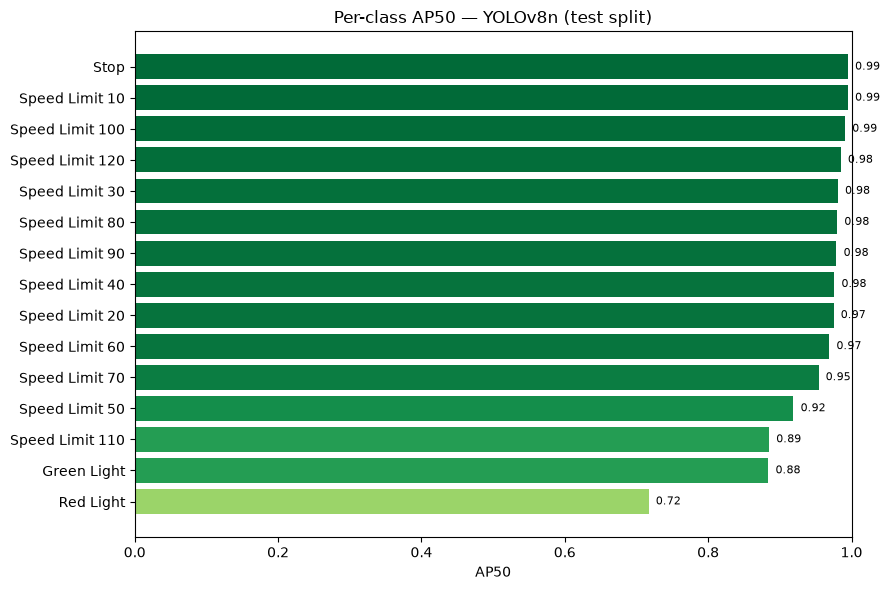

In [ ]:
# 6.2 · Per-class detection quality — AP50 on the test split
m_test = det_model.val(data=str(DET_YAML), split="test", verbose=False)
ap50 = np.nan_to_num(np.asarray(m_test.box.ap50, dtype=float), nan=0.0)  # per-class AP@IoU0.5
ap_df = (pd.DataFrame({"class": DET_CLASSES, "AP50": np.round(ap50, 3)})
          .sort_values("AP50"))
print(ap_df.to_string(index=False))
ap_df.to_csv(OUT_DIR / "per_class_ap50.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 6))
colors = plt.cm.RdYlGn(np.clip(ap_df["AP50"].values, 0, 1))
ax.barh(ap_df["class"], ap_df["AP50"], color=colors)
ax.set(title="Per-class AP50 — YOLOv8n (test split)", xlabel="AP50", xlim=(0, 1))
for y, v in enumerate(ap_df["AP50"]):
    ax.text(v + .01, y, f"{v:.2f}", va="center", fontsize=8)
plt.tight_layout(); plt.savefig(OUT_DIR / "per_class_ap50.png", dpi=150); plt.show()

## 7 · Wrap-up

| Requirement (*énoncé*) | Where it is answered |
|---|---|
| **Panneau détecté** | YOLOv8n boxes — §2.4 / §5 visuals |
| **Statistiques** | dataset balance, object sizes, objects/image — §6.1 |

**Files produced**
* `outputs/` — metrics CSVs, training curves, confusion matrices, per-class AP, error analysis, dataset stats, pipeline demo

**To go further** — larger detector (`yolov8s`), fully fresh detection (`USE_PRETRAINED=False`),
